# Sistema de clasificación de variaciones de precios agrícolas en Piura con KNN

### Fuentes de datos

- [Precios mayoristas y minoristas del Mercado Modelo de Piura](https://www.datosabiertos.gob.pe/dataset/precios-mayorista-y-minorista-del-mercado-modelo-de-piuragobierno-regional-piura-grp-0)
- [Datos meteorológicos diarios de NASA POWER](https://power.larc.nasa.gov/api/temporal/daily/point?parameters=PRECTOTCORR,T2M_MAX,T2M_MIN&community=AG&longitude=-80.63282&latitude=-5.19449&start=20240101&end=20260313&format=CSV)
- [Índice mensual Niño 1+2 de NOAA](https://psl.noaa.gov/data/correlation/nina1.anom.csv)

## 1. Limpieza de datos

### 1.1 Carga de librerías y archivos

Se cargan los tres CSV y se localizan automáticamente tanto en Google Colab como en la carpeta local del proyecto.

In [1]:
# Si Google Colab no tiene alguna biblioteca, descomentar y ejecutar una sola vez:
# %pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", palette="Set2")
RANDOM_STATE = 42

ARCHIVOS = {
    "mercado": "mimercado_dataset.csv",
    "clima": "POWER_Point_Daily_20240101_20260313_005d19S_080d63W_LST.csv",
    "nino": "nina1.anom.csv",
}

def localizar_archivo(nombre):
    candidatos = [
        Path.cwd() / "data" / "raw" / nombre,
        Path.cwd().parent / "data" / "raw" / nombre,
        Path.cwd() / nombre,
        Path("/content") / nombre,
    ]
    for ruta in candidatos:
        if ruta.exists():
            return ruta
    raise FileNotFoundError(
        f"No se encontró {nombre}. En Colab, cárguelo en /content y vuelva a ejecutar."
    )

rutas = {clave: localizar_archivo(nombre) for clave, nombre in ARCHIVOS.items()}
print("Archivos localizados:")
for clave, ruta in rutas.items():
    print(f"- {clave}: {ruta}")

Archivos localizados:
- mercado: C:\Users\jaime6693\OneDrive\Pictures\Desktop\Inteligencia artificial\precios-piura-knn\data\raw\mimercado_dataset.csv
- clima: C:\Users\jaime6693\OneDrive\Pictures\Desktop\Inteligencia artificial\precios-piura-knn\data\raw\POWER_Point_Daily_20240101_20260313_005d19S_080d63W_LST.csv
- nino: C:\Users\jaime6693\OneDrive\Pictures\Desktop\Inteligencia artificial\precios-piura-knn\data\raw\nina1.anom.csv


In [2]:
def leer_nasa_power(ruta):
    with open(ruta, "r", encoding="utf-8-sig") as f:
        lineas = f.readlines()
    fila_cabecera = next(
        i for i, linea in enumerate(lineas)
        if linea.strip().startswith("YEAR,DOY")
    )
    return pd.read_csv(ruta, skiprows=fila_cabecera)

mercado_raw = pd.read_csv(rutas["mercado"])
clima_raw = leer_nasa_power(rutas["clima"])
nino_raw = pd.read_csv(rutas["nino"], skipinitialspace=True)

print("Dimensiones originales:")
print(f"Mercado: {mercado_raw.shape}")
print(f"Clima:   {clima_raw.shape}")
print(f"Niño:    {nino_raw.shape}")

display(mercado_raw.head(3))
display(clima_raw.head(3))
display(nino_raw.head(3))

Dimensiones originales:
Mercado: (7464, 12)
Clima:   (803, 5)
Niño:    (948, 2)


,FECHA_CORTE,DEPARTAMENTO,PROVINCIA,DISTRITO,UBIGEO,FECHA_REGISTRO,PRODUCTO,PRECIO_MAYORISTA,PRECIO_MINORISTA,CATEGORIA,UNIDAD_MEDIDA_MAY,UNIDAD_MEDIDA_MIN
0,20260406,PIURA,PIURA,PIURA,200101,20260313,Melon coquito,2.46,3.05,Frutas,KILOGRAMO,KILOGRAMO
1,20260406,PIURA,PIURA,PIURA,200101,20260313,Uva alfonso lavalett,4.00,7.10,Frutas,KILOGRAMO,KILOGRAMO
2,20260406,PIURA,PIURA,PIURA,200101,20260313,Cebolla cabeza roja,1.92,4.25,Hortalizas,SACO,KILOGRAMO


,YEAR,DOY,PRECTOTCORR,T2M_MAX,T2M_MIN
0,2024,1,0.00,35.65,22.54
1,2024,2,0.11,35.15,22.10
2,2024,3,0.21,34.45,22.18


,Date,NINA12 missing value -99.99 https://psl.noaa.gov/data/timeseries/month/
0,1948-01-01,-1.03
1,1948-02-01,0.09
2,1948-03-01,-0.41


### 1.2 Revisión inicial

Antes de modificar los datos se revisan dimensiones, columnas, tipos, fechas, valores faltantes, duplicados, precios no positivos y códigos especiales de NASA y NOAA.

In [3]:
# Copias de trabajo para no modificar los datos originales
mercado = mercado_raw.copy()
clima = clima_raw.copy()
nino = nino_raw.copy()

# Fechas provisionales para la auditoría
mercado["FECHA"] = pd.to_datetime(
    mercado["FECHA_REGISTRO"].astype(str), format="%Y%m%d", errors="coerce"
)
clima["FECHA"] = pd.to_datetime(
    clima["YEAR"].astype(str) + "-" + clima["DOY"].astype(str),
    format="%Y-%j", errors="coerce"
)
nino.columns = ["FECHA", "NINO12"]
nino["FECHA"] = pd.to_datetime(nino["FECHA"], errors="coerce")
nino["NINO12"] = pd.to_numeric(nino["NINO12"], errors="coerce")

resumen_fuentes = pd.DataFrame({
    "Fuente": ["Mercado", "NASA POWER", "NOAA Niño 1+2"],
    "Filas": [len(mercado), len(clima), len(nino)],
    "Columnas": [mercado_raw.shape[1], clima_raw.shape[1], nino_raw.shape[1]],
    "Fecha mínima": [mercado["FECHA"].min(), clima["FECHA"].min(), nino["FECHA"].min()],
    "Fecha máxima": [mercado["FECHA"].max(), clima["FECHA"].max(), nino["FECHA"].max()],
    "Fechas únicas": [mercado["FECHA"].nunique(), clima["FECHA"].nunique(), nino["FECHA"].nunique()],
})
display(resumen_fuentes)

print("Tipos de datos del mercado:")
display(mercado_raw.dtypes.rename("tipo").to_frame())

print("Valores faltantes originales:")
display(pd.DataFrame({
    "Mercado": mercado_raw.isna().sum(),
    "Clima": clima_raw.isna().sum(),
    "Niño": nino_raw.isna().sum(),
}).fillna("—"))

,Fuente,Filas,Columnas,Fecha mínima,Fecha máxima,Fechas únicas
0,Mercado,7464,12,2024-01-08,2026-03-13,151
1,NASA POWER,803,5,2024-01-01,2026-03-13,803
2,NOAA Niño 1+2,948,2,1948-01-01,2026-12-01,948


Tipos de datos del mercado:


,tipo
FECHA_CORTE,int64
DEPARTAMENTO,object
PROVINCIA,object
DISTRITO,object
UBIGEO,int64
FECHA_REGISTRO,int64
PRODUCTO,object
PRECIO_MAYORISTA,float64
PRECIO_MINORISTA,float64
CATEGORIA,object


Valores faltantes originales:


,Mercado,Clima,Niño
CATEGORIA,0.0,—,—
DEPARTAMENTO,0.0,—,—
DISTRITO,0.0,—,—
DOY,—,0.0,—
Date,—,—,0.0
FECHA_CORTE,0.0,—,—
FECHA_REGISTRO,0.0,—,—
NINA12 missing value -99.99 https://psl.noaa.gov/data/timeseries/month/,—,—,0.0
PRECIO_MAYORISTA,0.0,—,—
PRECIO_MINORISTA,0.0,—,—


In [4]:
auditoria = {
    "duplicados_exactos_mercado": int(mercado_raw.duplicated().sum()),
    "duplicados_producto_fecha": int(mercado.duplicated(["PRODUCTO", "FECHA"]).sum()),
    "fechas_mercado_invalidas": int(mercado["FECHA"].isna().sum()),
    "precios_mayoristas_no_positivos": int((mercado["PRECIO_MAYORISTA"] <= 0).sum()),
    "precios_minoristas_no_positivos": int((mercado["PRECIO_MINORISTA"] <= 0).sum()),
    "duplicados_fecha_clima": int(clima["FECHA"].duplicated().sum()),
    "codigos_-999_clima": int((clima[["PRECTOTCORR", "T2M_MAX", "T2M_MIN"]] == -999).sum().sum()),
    "duplicados_fecha_nino": int(nino["FECHA"].duplicated().sum()),
    "codigos_-99.99_nino": int((nino["NINO12"] == -99.99).sum()),
}
display(pd.Series(auditoria, name="cantidad").to_frame())

print(f"Productos únicos: {mercado['PRODUCTO'].nunique()}")
print(f"Categorías únicas: {mercado['CATEGORIA'].nunique()}")
print(f"Fechas de mercado: {mercado['FECHA'].nunique()}")

print("\nUnidades mayoristas:")
display(mercado["UNIDAD_MEDIDA_MAY"].value_counts().rename("registros").to_frame())
print("Unidades minoristas:")
display(mercado["UNIDAD_MEDIDA_MIN"].value_counts().rename("registros").to_frame())

,cantidad
duplicados_exactos_mercado,0
duplicados_producto_fecha,0
fechas_mercado_invalidas,0
precios_mayoristas_no_positivos,8
precios_minoristas_no_positivos,9
duplicados_fecha_clima,0
codigos_-999_clima,0
duplicados_fecha_nino,0
codigos_-99.99_nino,0


Productos únicos: 51
Categorías únicas: 8
Fechas de mercado: 151

Unidades mayoristas:


,registros
UNIDAD_MEDIDA_MAY,
KILOGRAMO,4599
SACO NORMAL,604
SACO GRANDE,452
LITRO,302
MALLA MEDIANA,302
SACO,151
UNIDAD,151
CAJA,151
SACO MEDIANO,151


Unidades minoristas:


,registros
UNIDAD_MEDIDA_MIN,
KILOGRAMO,6559
LITRO,453
LATA,151
MALLA,151
UNIDAD,150


**Resultado de la revisión:** las tres fuentes cubren el periodo necesario. El mercado no tiene duplicados exactos, pero contiene algunos precios no positivos. Las unidades de medida se conservarán por separado.

### 1.3 Tratamiento de precios y organización de las series

Los precios iguales o inferiores a cero se convierten en faltantes y se retiran. Los precios mayoristas y minoristas se transforman en filas separadas, manteniendo el producto y su unidad. `FECHA_REGISTRO` es la fecha del precio; `FECHA_CORTE` no se utiliza como fecha de observación.

In [5]:
mercado_limpio = mercado_raw.copy()
mercado_limpio["FECHA"] = pd.to_datetime(
    mercado_limpio["FECHA_REGISTRO"].astype(str),
    format="%Y%m%d", errors="coerce"
)

columnas_texto = [
    "DEPARTAMENTO", "PROVINCIA", "DISTRITO", "PRODUCTO", "CATEGORIA",
    "UNIDAD_MEDIDA_MAY", "UNIDAD_MEDIDA_MIN"
]
for col in columnas_texto:
    mercado_limpio[col] = mercado_limpio[col].astype("string").str.strip().str.replace(r"\s+", " ", regex=True)

for col in ["PRECIO_MAYORISTA", "PRECIO_MINORISTA"]:
    mercado_limpio[col] = pd.to_numeric(mercado_limpio[col], errors="coerce")
    mercado_limpio.loc[mercado_limpio[col] <= 0, col] = np.nan

mayorista = mercado_limpio[[
    "FECHA", "PRODUCTO", "CATEGORIA", "PRECIO_MAYORISTA", "UNIDAD_MEDIDA_MAY"
]].rename(columns={
    "PRECIO_MAYORISTA": "PRECIO",
    "UNIDAD_MEDIDA_MAY": "UNIDAD_MEDIDA"
})
mayorista["TIPO_PRECIO"] = "MAYORISTA"

minorista = mercado_limpio[[
    "FECHA", "PRODUCTO", "CATEGORIA", "PRECIO_MINORISTA", "UNIDAD_MEDIDA_MIN"
]].rename(columns={
    "PRECIO_MINORISTA": "PRECIO",
    "UNIDAD_MEDIDA_MIN": "UNIDAD_MEDIDA"
})
minorista["TIPO_PRECIO"] = "MINORISTA"

precios = pd.concat([mayorista, minorista], ignore_index=True)
antes = len(precios)
precios = precios.dropna(subset=["FECHA", "PRODUCTO", "PRECIO", "UNIDAD_MEDIDA"]).copy()
precios = precios.sort_values(["PRODUCTO", "TIPO_PRECIO", "UNIDAD_MEDIDA", "FECHA"])

CLAVES_SERIE = ["PRODUCTO", "TIPO_PRECIO", "UNIDAD_MEDIDA"]
duplicados_serie_fecha = precios.duplicated(CLAVES_SERIE + ["FECHA"]).sum()

print(f"Filas en formato largo antes de filtrar: {antes:,}")
print(f"Filas válidas después de filtrar:       {len(precios):,}")
print(f"Filas retiradas:                        {antes - len(precios):,}")
print(f"Duplicados serie-fecha:                 {duplicados_serie_fecha}")
display(precios.head())

Filas en formato largo antes de filtrar: 14,928
Filas válidas después de filtrar:       14,911
Filas retiradas:                        17
Duplicados serie-fecha:                 0


,FECHA,PRODUCTO,CATEGORIA,PRECIO,UNIDAD_MEDIDA,TIPO_PRECIO
7427,2024-01-08,Aceite clasico botella 900 ml,Agro-industriales,11.40,CAJA CHICA,MAYORISTA
7370,2024-03-01,Aceite clasico botella 900 ml,Agro-industriales,9.00,CAJA CHICA,MAYORISTA
7337,2024-03-04,Aceite clasico botella 900 ml,Agro-industriales,9.00,CAJA CHICA,MAYORISTA
7310,2024-05-13,Aceite clasico botella 900 ml,Agro-industriales,10.42,CAJA CHICA,MAYORISTA
7257,2024-05-15,Aceite clasico botella 900 ml,Agro-industriales,10.42,CAJA CHICA,MAYORISTA


**Resultado de la limpieza:** no se imputan precios porque hacerlo modificaría artificialmente las variaciones. Cada serie queda identificada por producto, tipo de precio y unidad de medida.

## 2. Análisis exploratorio

Se revisan la cantidad de observaciones por categoría y producto, algunos historiales de precios y los días existentes entre fechas consecutivas.

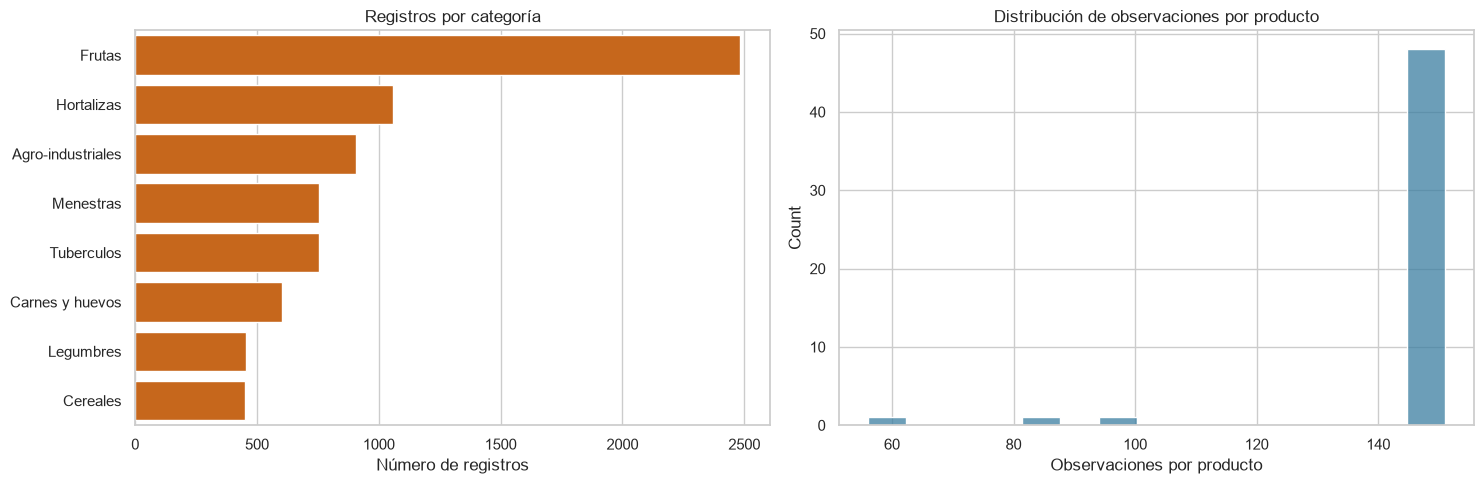

,observaciones
count,51.000000
mean,146.352941
std,17.657660
min,56.000000
25%,150.000000
50%,151.000000
75%,151.000000
max,151.000000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

orden_cat = mercado["CATEGORIA"].value_counts().index
sns.countplot(data=mercado, y="CATEGORIA", order=orden_cat, ax=axes[0], color="#E26400")
axes[0].set_title("Registros por categoría")
axes[0].set_xlabel("Número de registros")
axes[0].set_ylabel("")

obs_producto = mercado.groupby("PRODUCTO").size()
sns.histplot(obs_producto, bins=15, ax=axes[1], color="#3B7EA1")
axes[1].set_title("Distribución de observaciones por producto")
axes[1].set_xlabel("Observaciones por producto")

plt.tight_layout()
plt.show()

display(obs_producto.describe().rename("observaciones").to_frame())

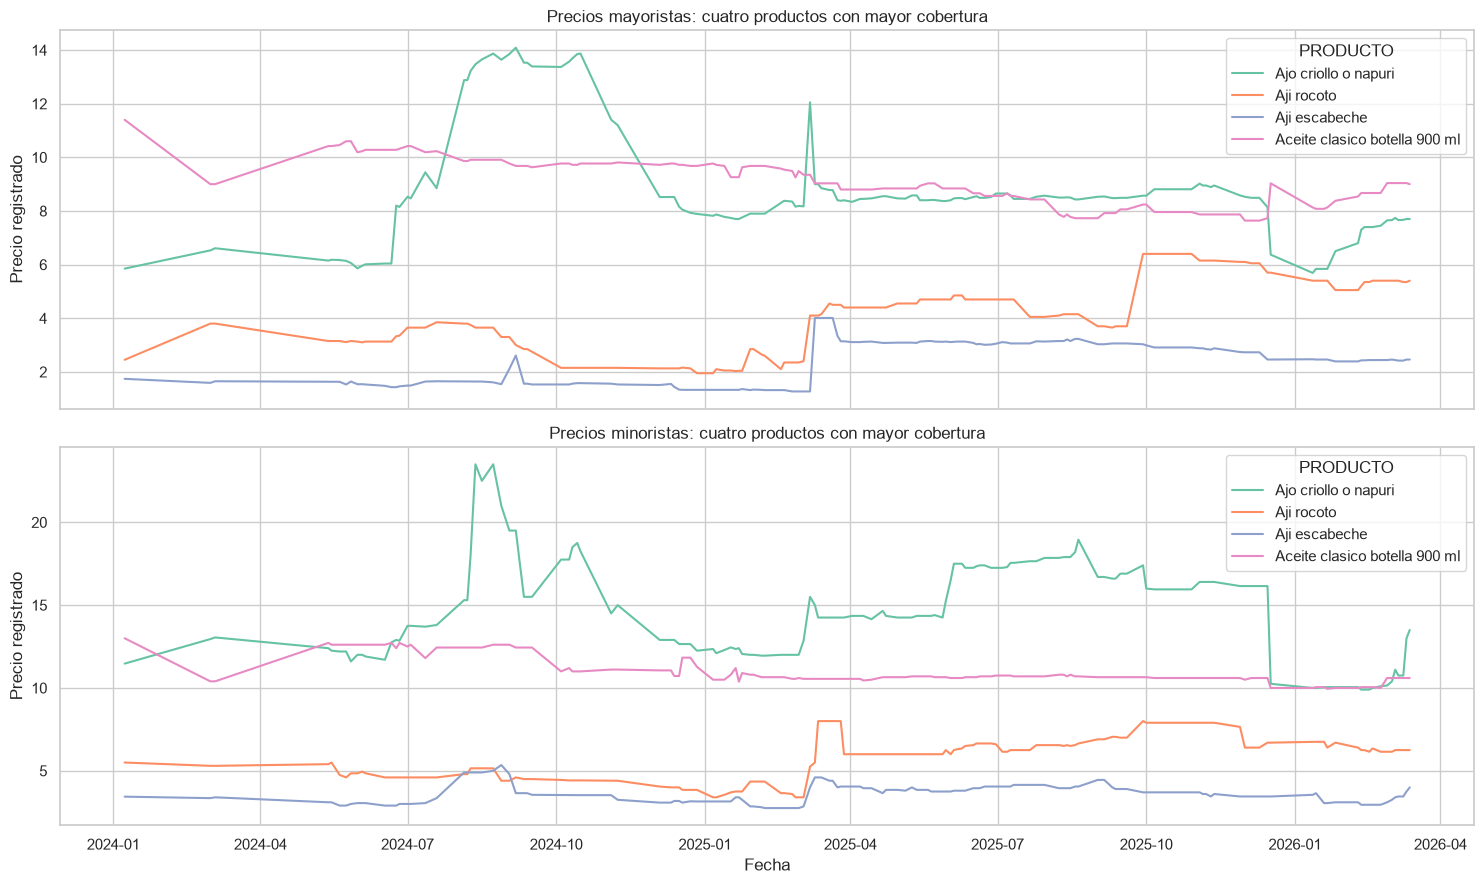

In [7]:
productos_muestra = obs_producto.sort_values(ascending=False).head(4).index
muestra = mercado[mercado["PRODUCTO"].isin(productos_muestra)].copy()

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
sns.lineplot(data=muestra, x="FECHA", y="PRECIO_MAYORISTA", hue="PRODUCTO", ax=axes[0])
axes[0].set_title("Precios mayoristas: cuatro productos con mayor cobertura")
axes[0].set_ylabel("Precio registrado")

sns.lineplot(data=muestra, x="FECHA", y="PRECIO_MINORISTA", hue="PRODUCTO", ax=axes[1])
axes[1].set_title("Precios minoristas: cuatro productos con mayor cobertura")
axes[1].set_ylabel("Precio registrado")
axes[1].set_xlabel("Fecha")

plt.tight_layout()
plt.show()

,días entre fechas generales
count,150.000000
mean,5.300000
std,7.845616
min,2.000000
25%,2.000000
50%,3.000000
75%,5.000000
max,70.000000


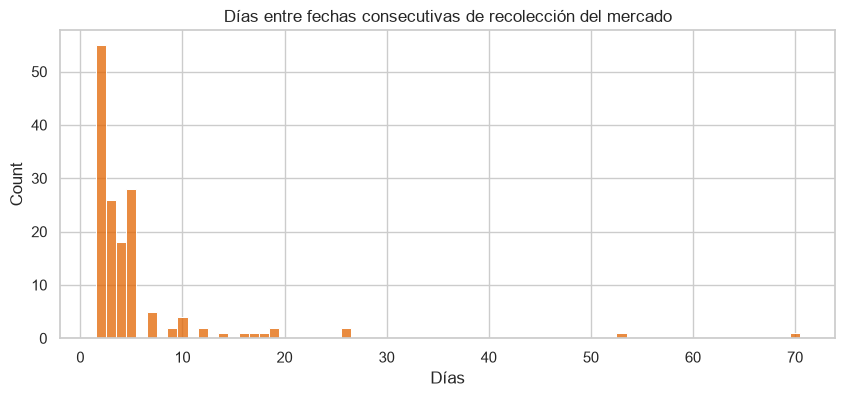

In [8]:
fechas_mercado = np.sort(mercado["FECHA"].dropna().unique())
intervalos = pd.Series(fechas_mercado).diff().dt.days.dropna()

display(intervalos.describe().rename("días entre fechas generales").to_frame())

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(intervalos, discrete=True, ax=ax, color="#E26400")
ax.set_title("Días entre fechas consecutivas de recolección del mercado")
ax.set_xlabel("Días")
plt.show()

**Resultado del análisis exploratorio:** las fechas de recolección son irregulares. Por eso el objetivo será predecir el siguiente registro disponible y no un número fijo de días en el futuro.

## 3. Construcción de variables históricas

Para cada serie se calculan el precio actual, dos precios anteriores, la última variación, estadísticas móviles y los días transcurridos. Los valores futuros se crean únicamente para formar la etiqueta y nunca se usan como predictores.

In [9]:
precios = precios.sort_values(CLAVES_SERIE + ["FECHA"]).copy()
grupos = precios.groupby(CLAVES_SERIE, sort=False, group_keys=False)

precios["PRECIO_ACTUAL"] = precios["PRECIO"]
precios["PRECIO_LAG1"] = grupos["PRECIO"].shift(1)
precios["PRECIO_LAG2"] = grupos["PRECIO"].shift(2)
precios["VAR_PCT_ANT"] = (precios["PRECIO_ACTUAL"] / precios["PRECIO_LAG1"] - 1) * 100
precios["MEDIA_MOVIL_3"] = grupos["PRECIO"].transform(
    lambda s: s.shift(1).rolling(3, min_periods=2).mean()
)
precios["STD_MOVIL_3"] = grupos["PRECIO"].transform(
    lambda s: s.shift(1).rolling(3, min_periods=2).std()
)
precios["DIAS_DESDE_ANT"] = grupos["FECHA"].diff().dt.days
precios["MES"] = precios["FECHA"].dt.month
precios["DIA_SEMANA"] = precios["FECHA"].dt.dayofweek

# Valores futuros: se crean únicamente para formar la etiqueta, nunca como predictores.
precios["FECHA_OBJETIVO"] = grupos["FECHA"].shift(-1)
precios["PRECIO_SIGUIENTE"] = grupos["PRECIO"].shift(-1)
precios["DIAS_HASTA_OBJETIVO"] = (precios["FECHA_OBJETIVO"] - precios["FECHA"]).dt.days
precios["VAR_SIG_PCT"] = (precios["PRECIO_SIGUIENTE"] / precios["PRECIO_ACTUAL"] - 1) * 100

cols_ver = CLAVES_SERIE + [
    "FECHA", "PRECIO_ACTUAL", "PRECIO_LAG1", "PRECIO_LAG2",
    "VAR_PCT_ANT", "MEDIA_MOVIL_3", "FECHA_OBJETIVO", "VAR_SIG_PCT"
]
display(precios[cols_ver].head(8))

,PRODUCTO,TIPO_PRECIO,UNIDAD_MEDIDA,FECHA,PRECIO_ACTUAL,PRECIO_LAG1,PRECIO_LAG2,VAR_PCT_ANT,MEDIA_MOVIL_3,FECHA_OBJETIVO,VAR_SIG_PCT
7427,Aceite clasico botella 900 ml,MAYORISTA,CAJA CHICA,2024-01-08,11.40,NaN,NaN,NaN,NaN,2024-03-01,-21.052632
7370,Aceite clasico botella 900 ml,MAYORISTA,CAJA CHICA,2024-03-01,9.00,11.40,NaN,-21.052632,NaN,2024-03-04,0.000000
7337,Aceite clasico botella 900 ml,MAYORISTA,CAJA CHICA,2024-03-04,9.00,9.00,11.40,0.000000,10.200000,2024-05-13,15.777778
7310,Aceite clasico botella 900 ml,MAYORISTA,CAJA CHICA,2024-05-13,10.42,9.00,9.00,15.777778,9.800000,2024-05-15,0.000000
7257,Aceite clasico botella 900 ml,MAYORISTA,CAJA CHICA,2024-05-15,10.42,10.42,9.00,0.000000,9.473333,2024-05-20,0.383877
7201,Aceite clasico botella 900 ml,MAYORISTA,CAJA CHICA,2024-05-20,10.46,10.42,10.42,0.383877,9.946667,2024-05-24,1.338432
7158,Aceite clasico botella 900 ml,MAYORISTA,CAJA CHICA,2024-05-24,10.60,10.46,10.42,1.338432,10.433333,2024-05-27,0.000000
7122,Aceite clasico botella 900 ml,MAYORISTA,CAJA CHICA,2024-05-27,10.60,10.60,10.46,0.000000,10.493333,2024-05-31,-3.867925


## 4. Limpieza e integración de los datos climáticos

### 4.1 NASA POWER

Los códigos `-999` se tratan como faltantes. Se calculan lluvia y temperatura del día anterior, además de acumulados o promedios de 7 y 30 días. La fecha disponible se desplaza un día para impedir el uso de clima futuro.

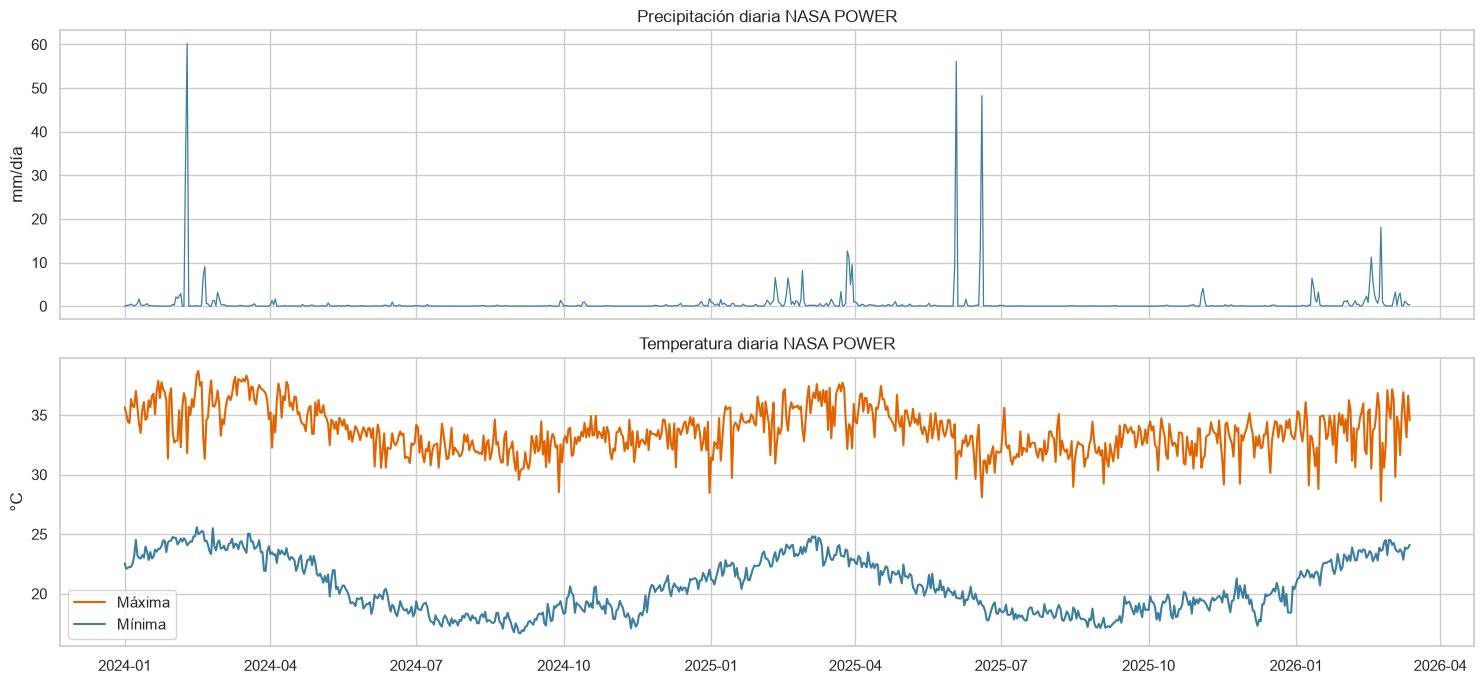

In [10]:
clima = clima_raw.copy()
clima["FECHA_CLIMA"] = pd.to_datetime(
    clima["YEAR"].astype(str) + "-" + clima["DOY"].astype(str),
    format="%Y-%j", errors="coerce"
)
vars_clima_base = ["PRECTOTCORR", "T2M_MAX", "T2M_MIN"]
for col in vars_clima_base:
    clima[col] = pd.to_numeric(clima[col], errors="coerce").replace(-999, np.nan)

clima = clima.sort_values("FECHA_CLIMA").drop_duplicates("FECHA_CLIMA")
clima["LLUVIA_DIA_ANT"] = clima["PRECTOTCORR"]
clima["TMAX_DIA_ANT"] = clima["T2M_MAX"]
clima["TMIN_DIA_ANT"] = clima["T2M_MIN"]
clima["LLUVIA_ACUM_7D"] = clima["PRECTOTCORR"].rolling(7, min_periods=1).sum()
clima["LLUVIA_ACUM_30D"] = clima["PRECTOTCORR"].rolling(30, min_periods=1).sum()
clima["TMAX_MEDIA_7D"] = clima["T2M_MAX"].rolling(7, min_periods=1).mean()
clima["TMIN_MEDIA_7D"] = clima["T2M_MIN"].rolling(7, min_periods=1).mean()
clima["FECHA_DISP_CLIMA"] = clima["FECHA_CLIMA"] + np.timedelta64(1, "D")

vars_clima = [
    "LLUVIA_DIA_ANT", "TMAX_DIA_ANT", "TMIN_DIA_ANT",
    "LLUVIA_ACUM_7D", "LLUVIA_ACUM_30D", "TMAX_MEDIA_7D", "TMIN_MEDIA_7D"
]

fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
axes[0].plot(clima["FECHA_CLIMA"], clima["PRECTOTCORR"], color="#3B7EA1", linewidth=0.9)
axes[0].set_title("Precipitación diaria NASA POWER")
axes[0].set_ylabel("mm/día")
axes[1].plot(clima["FECHA_CLIMA"], clima["T2M_MAX"], label="Máxima", color="#E26400")
axes[1].plot(clima["FECHA_CLIMA"], clima["T2M_MIN"], label="Mínima", color="#3B7EA1")
axes[1].set_title("Temperatura diaria NASA POWER")
axes[1].set_ylabel("°C")
axes[1].legend()
plt.tight_layout()
plt.show()

### 4.2 Índice Niño 1+2

El código `-99.99` se trata como faltante. Cada anomalía mensual se utiliza desde el comienzo del mes siguiente, aplicando un desfase conservador de un mes.

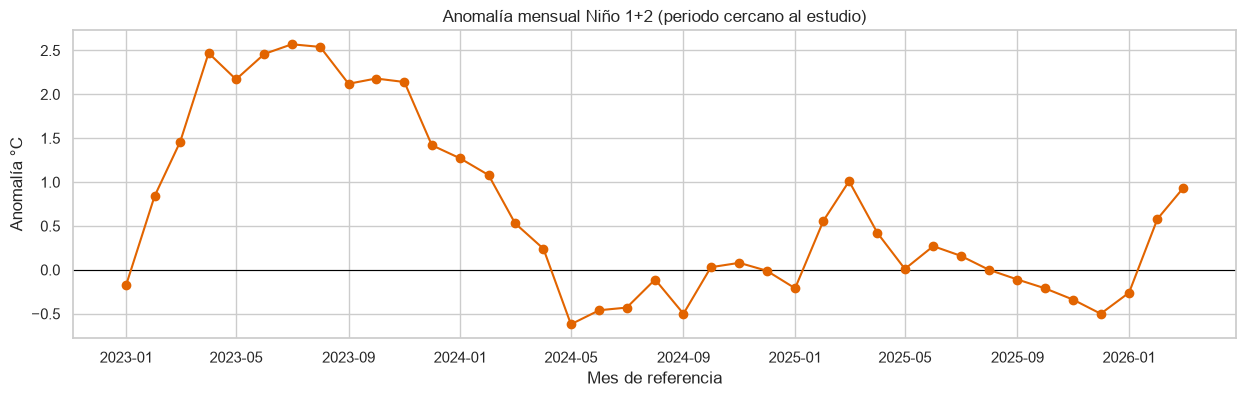

In [11]:
nino = nino_raw.copy()
nino.columns = ["FECHA_NINO", "NINO12"]
nino["FECHA_NINO"] = pd.to_datetime(nino["FECHA_NINO"], errors="coerce")
nino["NINO12"] = pd.to_numeric(nino["NINO12"], errors="coerce").replace(-99.99, np.nan)
nino = nino.dropna(subset=["FECHA_NINO", "NINO12"]).sort_values("FECHA_NINO")
nino["FECHA_DISP_NINO"] = nino["FECHA_NINO"] + pd.offsets.MonthBegin(1)

nino_periodo = nino[nino["FECHA_NINO"].between("2023-01-01", "2026-03-31")]
fig, ax = plt.subplots(figsize=(15, 4))
ax.axhline(0, color="black", linewidth=0.8)
ax.plot(nino_periodo["FECHA_NINO"], nino_periodo["NINO12"], marker="o", color="#E26400")
ax.set_title("Anomalía mensual Niño 1+2 (periodo cercano al estudio)")
ax.set_ylabel("Anomalía °C")
ax.set_xlabel("Mes de referencia")
plt.show()

### 4.3 Consolidación de las tres fuentes

Cada registro de precio recibe el dato climático y oceánico más reciente que ya se encontraba disponible en esa fecha.

In [12]:
datos = precios.sort_values("FECHA").copy()

clima_union = clima[["FECHA_CLIMA", "FECHA_DISP_CLIMA"] + vars_clima].sort_values("FECHA_DISP_CLIMA")
datos = pd.merge_asof(
    datos,
    clima_union,
    left_on="FECHA",
    right_on="FECHA_DISP_CLIMA",
    direction="backward"
)

nino_union = nino[["FECHA_NINO", "FECHA_DISP_NINO", "NINO12"]].sort_values("FECHA_DISP_NINO")
datos = pd.merge_asof(
    datos.sort_values("FECHA"),
    nino_union,
    left_on="FECHA",
    right_on="FECHA_DISP_NINO",
    direction="backward"
)

assert (datos["FECHA_CLIMA"] < datos["FECHA"]).all(), "Se detectó clima del mismo día o futuro."
assert (datos["FECHA_NINO"] < datos["FECHA"].dt.to_period("M").dt.start_time).all(), "El Niño 1+2 no tiene el desfase previsto."

cobertura_integracion = pd.Series({
    "filas_con_clima_completo": int(datos[vars_clima].notna().all(axis=1).sum()),
    "filas_con_nino12": int(datos["NINO12"].notna().sum()),
    "total_filas_precios": len(datos),
    "fecha_clima_mas_reciente_usada": datos["FECHA_CLIMA"].max(),
    "mes_nino_mas_reciente_usado": datos["FECHA_NINO"].max(),
})
display(cobertura_integracion.rename("resultado").to_frame())

display(datos[[
    "FECHA", "PRODUCTO", "TIPO_PRECIO", "PRECIO_ACTUAL",
    "FECHA_CLIMA", "LLUVIA_ACUM_7D", "FECHA_NINO", "NINO12"
]].head())

,resultado
filas_con_clima_completo,14911
filas_con_nino12,14911
total_filas_precios,14911
fecha_clima_mas_reciente_usada,2026-03-12 00:00:00
mes_nino_mas_reciente_usado,2026-02-01 00:00:00


,FECHA,PRODUCTO,TIPO_PRECIO,PRECIO_ACTUAL,FECHA_CLIMA,LLUVIA_ACUM_7D,FECHA_NINO,NINO12
0,2024-01-08,Aceite clasico botella 900 ml,MAYORISTA,11.40,2024-01-07,1.25,2023-12-01,1.42
1,2024-01-08,Platano seda congo,MAYORISTA,1.80,2024-01-07,1.25,2023-12-01,1.42
2,2024-01-08,Arroz extra,MAYORISTA,2.78,2024-01-07,1.25,2023-12-01,1.42
3,2024-01-08,Lenteja,MINORISTA,7.40,2024-01-07,1.25,2023-12-01,1.42
4,2024-01-08,Fideos nicolini tallarin,MINORISTA,5.50,2024-01-07,1.25,2023-12-01,1.42


**Resultado de la consolidación:** no existen registros con clima futuro ni con Niño 1+2 sin el desfase establecido. La integración temporal es completa para las observaciones utilizadas.

## 5. Construcción de la variable objetivo

La variación hacia el siguiente precio se clasifica de esta manera:

- **SUBE:** variación superior a +1 %.
- **BAJA:** variación inferior a −1 %.
- **ESTABLE:** variación entre −1 % y +1 %.

También se muestra cómo cambia la distribución con umbrales de 0.5 %, 1 % y 2 %.

,BAJA,ESTABLE,SUBE
umbral_pct,,,
0.5,2706,8879,3224
1.0,2280,9838,2691
2.0,1604,11382,1823


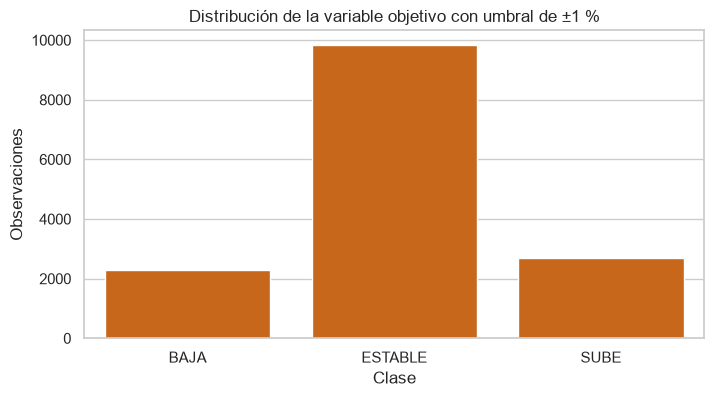

,días hasta el objetivo
count,14809.000000
mean,5.352691
std,8.356015
min,2.000000
25%,2.000000
50%,3.000000
75%,5.000000
max,194.000000


In [13]:
def clasificar_variacion(serie, umbral=1.0):
    return np.select(
        [serie > umbral, serie < -umbral],
        ["SUBE", "BAJA"],
        default="ESTABLE"
    )

# Solo se clasifica cuando existe precio siguiente.
datos["CLASE"] = pd.NA
mask_obj = datos["VAR_SIG_PCT"].notna()
datos.loc[mask_obj, "CLASE"] = clasificar_variacion(datos.loc[mask_obj, "VAR_SIG_PCT"], 1.0)

sensibilidad = []
for umbral in [0.5, 1.0, 2.0]:
    clases = pd.Series(clasificar_variacion(datos.loc[mask_obj, "VAR_SIG_PCT"], umbral))
    conteos = clases.value_counts()
    sensibilidad.append({
        "umbral_pct": umbral,
        "BAJA": int(conteos.get("BAJA", 0)),
        "ESTABLE": int(conteos.get("ESTABLE", 0)),
        "SUBE": int(conteos.get("SUBE", 0)),
    })
display(pd.DataFrame(sensibilidad).set_index("umbral_pct"))

fig, ax = plt.subplots(figsize=(8, 4))
orden_clases = ["BAJA", "ESTABLE", "SUBE"]
sns.countplot(data=datos[mask_obj], x="CLASE", order=orden_clases, ax=ax, color="#E26400")
ax.set_title("Distribución de la variable objetivo con umbral de ±1 %")
ax.set_xlabel("Clase")
ax.set_ylabel("Observaciones")
plt.show()

display(datos.loc[mask_obj, "DIAS_HASTA_OBJETIVO"].describe().rename("días hasta el objetivo").to_frame())

**Resultado de la variable objetivo:** existe predominio de la clase ESTABLE. Por esta razón no se evaluará únicamente el accuracy; también se utilizarán balanced accuracy y F1 macro.

## 6. Preparación de los datos para KNN

El Modelo A utiliza precios históricos, calendario y características del producto. El Modelo B utiliza las mismas variables más clima y Niño 1+2. Ambos modelos trabajan con exactamente las mismas observaciones completas.

In [14]:
categoricas = ["PRODUCTO", "CATEGORIA", "TIPO_PRECIO", "UNIDAD_MEDIDA"]
numericas_A = [
    "PRECIO_ACTUAL", "PRECIO_LAG1", "PRECIO_LAG2", "VAR_PCT_ANT",
    "MEDIA_MOVIL_3", "STD_MOVIL_3", "DIAS_DESDE_ANT", "MES", "DIA_SEMANA"
]
numericas_B = numericas_A + vars_clima + ["NINO12"]
features_A = numericas_A + categoricas
features_B = numericas_B + categoricas

requeridas = features_B + ["CLASE", "FECHA", "FECHA_OBJETIVO"]
modelo_df = datos.dropna(subset=requeridas).copy()
modelo_df["CLASE"] = modelo_df["CLASE"].astype(str)
modelo_df = modelo_df.sort_values(["FECHA_OBJETIVO", "FECHA"])

print(f"Filas de precios válidas: {len(datos):,}")
print(f"Filas evaluables comunes A/B: {len(modelo_df):,}")
print(f"Series representadas: {modelo_df[CLAVES_SERIE].drop_duplicates().shape[0]}")
display(modelo_df[features_B + ["FECHA", "FECHA_OBJETIVO", "CLASE"]].head())

Filas de precios válidas: 14,911
Filas evaluables comunes A/B: 14,605
Series representadas: 102


,PRECIO_ACTUAL,PRECIO_LAG1,PRECIO_LAG2,VAR_PCT_ANT,MEDIA_MOVIL_3,STD_MOVIL_3,DIAS_DESDE_ANT,MES,DIA_SEMANA,LLUVIA_DIA_ANT,TMAX_DIA_ANT,TMIN_DIA_ANT,LLUVIA_ACUM_7D,LLUVIA_ACUM_30D,TMAX_MEDIA_7D,TMIN_MEDIA_7D,NINO12,PRODUCTO,CATEGORIA,TIPO_PRECIO,UNIDAD_MEDIDA,FECHA,FECHA_OBJETIVO,CLASE
197,8.40,8.25,8.10,1.818182,8.175,0.106066,3.0,3,0,0.4,34.24,24.03,7.42,126.06,35.29,24.0,1.08,Palta fuerte,Frutas,MINORISTA,KILOGRAMO,2024-03-04,2024-05-13,SUBE
198,1.70,1.70,1.98,0.000000,1.840,0.197990,3.0,3,0,0.4,34.24,24.03,7.42,126.06,35.29,24.0,1.08,Papaya,Frutas,MAYORISTA,KILOGRAMO,2024-03-04,2024-05-13,SUBE
199,6.05,6.05,6.12,0.000000,6.085,0.049497,3.0,3,0,0.4,34.24,24.03,7.42,126.06,35.29,24.0,1.08,Azucar blanca nacional (granel),Agro-industriales,MINORISTA,KILOGRAMO,2024-03-04,2024-05-13,SUBE
200,7.35,7.35,6.40,0.000000,6.875,0.671751,3.0,3,0,0.4,34.24,24.03,7.42,126.06,35.29,24.0,1.08,Leche fresca,Agro-industriales,MINORISTA,LITRO,2024-03-04,2024-05-13,SUBE
201,3.40,3.35,3.44,1.492537,3.395,0.063640,3.0,3,0,0.4,34.24,24.03,7.42,126.06,35.29,24.0,1.08,Aji escabeche,Hortalizas,MINORISTA,MALLA,2024-03-04,2024-05-13,BAJA


### 6.1 División cronológica

Las filas se dividen por la fecha correspondiente al precio objetivo: 70 % para entrenamiento, 15 % para validación y 15 % para prueba. No se mezclan aleatoriamente registros futuros con registros pasados.

In [15]:
fechas_objetivo = np.sort(modelo_df["FECHA_OBJETIVO"].unique())
n_fechas = len(fechas_objetivo)
i_train = max(1, int(n_fechas * 0.70))
i_val = max(i_train + 1, int(n_fechas * 0.85))
fin_train = pd.Timestamp(fechas_objetivo[i_train - 1])
fin_val = pd.Timestamp(fechas_objetivo[i_val - 1])

mask_train = modelo_df["FECHA_OBJETIVO"] <= fin_train
mask_val = (modelo_df["FECHA_OBJETIVO"] > fin_train) & (modelo_df["FECHA_OBJETIVO"] <= fin_val)
mask_test = modelo_df["FECHA_OBJETIVO"] > fin_val

train_df = modelo_df[mask_train].copy()
val_df = modelo_df[mask_val].copy()
test_df = modelo_df[mask_test].copy()

particiones = pd.DataFrame({
    "Partición": ["Entrenamiento", "Validación", "Prueba"],
    "Filas": [len(train_df), len(val_df), len(test_df)],
    "Fecha objetivo mínima": [train_df.FECHA_OBJETIVO.min(), val_df.FECHA_OBJETIVO.min(), test_df.FECHA_OBJETIVO.min()],
    "Fecha objetivo máxima": [train_df.FECHA_OBJETIVO.max(), val_df.FECHA_OBJETIVO.max(), test_df.FECHA_OBJETIVO.max()],
})
display(particiones)

assert train_df["FECHA_OBJETIVO"].max() < val_df["FECHA_OBJETIVO"].min()
assert val_df["FECHA_OBJETIVO"].max() < test_df["FECHA_OBJETIVO"].min()

,Partición,Filas,Fecha objetivo mínima,Fecha objetivo máxima
0,Entrenamiento,10132,2024-05-13,2025-08-08
1,Validación,2176,2025-08-11,2025-11-28
2,Prueba,2297,2025-12-01,2026-03-13


### 6.2 Normalización y codificación

Las variables numéricas se estandarizan y las categóricas se convierten mediante One-Hot Encoding. El preprocesamiento se ajusta exclusivamente con entrenamiento.

In [16]:
def crear_preprocesador(numericas, categoricas):
    return ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
    ], remainder="drop")

def preparar_matrices(features, numericas):
    pre = crear_preprocesador(numericas, categoricas)
    X_train_t = pre.fit_transform(train_df[features])
    X_val_t = pre.transform(val_df[features])
    return pre, X_train_t, X_val_t

y_train = train_df["CLASE"]
y_val = val_df["CLASE"]
y_test = test_df["CLASE"]

pre_A, X_train_A_t, X_val_A_t = preparar_matrices(features_A, numericas_A)
pre_B, X_train_B_t, X_val_B_t = preparar_matrices(features_B, numericas_B)

print("Matriz transformada A:", X_train_A_t.shape)
print("Matriz transformada B:", X_train_B_t.shape)

Matriz transformada A: (10132, 85)
Matriz transformada B: (10132, 93)


## 7. Entrenamiento KNN

Se comparan distintos valores de K con distancia Manhattan y euclidiana. La selección se realiza con balanced accuracy de validación; el conjunto de prueba todavía no participa.

Mejores combinaciones del Modelo A:


,modelo,k,p,distancia,balanced_accuracy_val,f1_macro_val,accuracy_val
0,A: sin clima,7,1,Manhattan,0.368212,0.364416,0.628217
1,A: sin clima,5,1,Manhattan,0.367903,0.366841,0.602482
2,A: sin clima,9,1,Manhattan,0.366846,0.358052,0.645680
3,A: sin clima,11,1,Manhattan,0.366836,0.354592,0.656710
4,A: sin clima,15,1,Manhattan,0.366820,0.347652,0.673254
5,A: sin clima,5,2,Euclidiana,0.365559,0.364763,0.589154
6,A: sin clima,3,1,Manhattan,0.364904,0.364721,0.578585


Mejores combinaciones del Modelo B:


,modelo,k,p,distancia,balanced_accuracy_val,f1_macro_val,accuracy_val
0,B: con clima,3,1,Manhattan,0.389706,0.389233,0.573989
1,B: con clima,5,1,Manhattan,0.386911,0.387661,0.607537
2,B: con clima,3,2,Euclidiana,0.378515,0.377682,0.556066
3,B: con clima,7,1,Manhattan,0.376995,0.375180,0.631434
4,B: con clima,9,2,Euclidiana,0.370578,0.366333,0.628217
5,B: con clima,5,2,Euclidiana,0.369994,0.369229,0.582261
6,B: con clima,9,1,Manhattan,0.368794,0.362669,0.637408


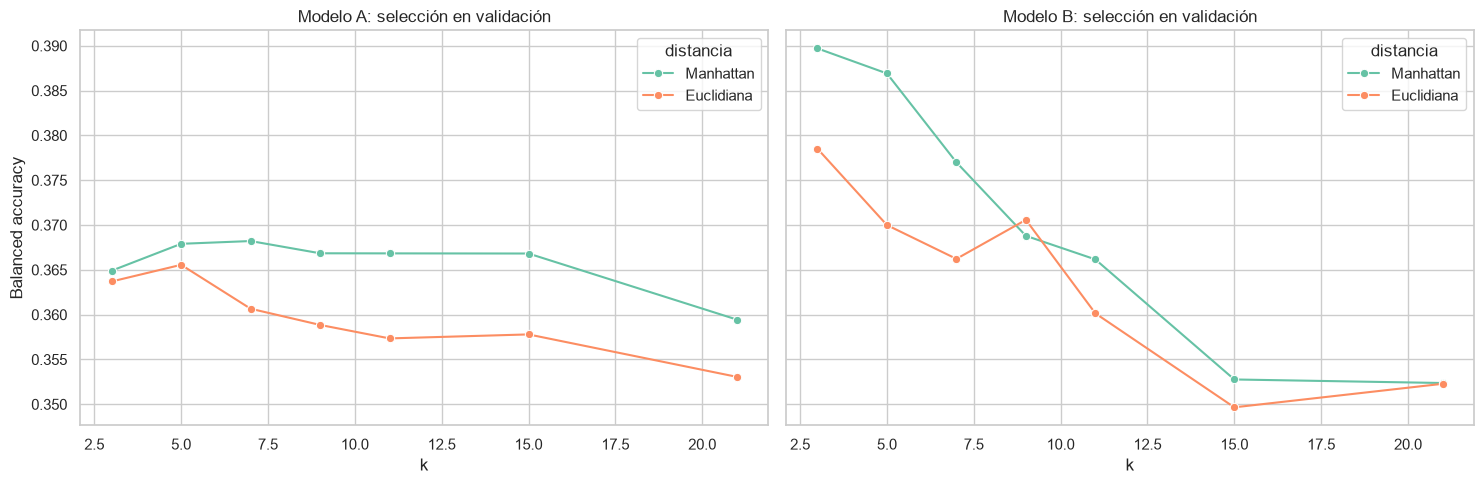

In [17]:
def buscar_knn(X_train_t, X_val_t, y_train, y_val, nombre_modelo):
    filas = []
    for k in [3, 5, 7, 9, 11, 15, 21]:
        for p, distancia in [(1, "Manhattan"), (2, "Euclidiana")]:
            knn = KNeighborsClassifier(n_neighbors=k, p=p, weights="distance", n_jobs=-1)
            knn.fit(X_train_t, y_train)
            pred = knn.predict(X_val_t)
            filas.append({
                "modelo": nombre_modelo,
                "k": k,
                "p": p,
                "distancia": distancia,
                "balanced_accuracy_val": balanced_accuracy_score(y_val, pred),
                "f1_macro_val": f1_score(y_val, pred, average="macro", zero_division=0),
                "accuracy_val": accuracy_score(y_val, pred),
            })
    return pd.DataFrame(filas).sort_values(
        ["balanced_accuracy_val", "f1_macro_val"], ascending=False
    ).reset_index(drop=True)

busqueda_A = buscar_knn(X_train_A_t, X_val_A_t, y_train, y_val, "A: sin clima")
busqueda_B = buscar_knn(X_train_B_t, X_val_B_t, y_train, y_val, "B: con clima")
busqueda = pd.concat([busqueda_A, busqueda_B], ignore_index=True)

print("Mejores combinaciones del Modelo A:")
display(busqueda_A.head(7))
print("Mejores combinaciones del Modelo B:")
display(busqueda_B.head(7))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, tabla, titulo in zip(axes, [busqueda_A, busqueda_B], ["Modelo A", "Modelo B"]):
    sns.lineplot(data=tabla, x="k", y="balanced_accuracy_val", hue="distancia", marker="o", ax=ax)
    ax.set_title(f"{titulo}: selección en validación")
    ax.set_ylabel("Balanced accuracy")
plt.tight_layout()
plt.show()

**Resultado del entrenamiento:** se selecciona de forma independiente la mejor combinación de K y distancia para el Modelo A y el Modelo B.

## 8. Evaluación de los modelos

Los modelos elegidos se vuelven a entrenar con entrenamiento más validación. Se comparan contra una referencia que siempre predice la clase mayoritaria.

In [18]:
mejor_A = busqueda_A.iloc[0]
mejor_B = busqueda_B.iloc[0]
train_val_df = pd.concat([train_df, val_df]).sort_values("FECHA_OBJETIVO")

def crear_pipeline_final(numericas, k, p, estimador="knn"):
    pre = crear_preprocesador(numericas, categoricas)
    if estimador == "knn":
        clf = KNeighborsClassifier(
            n_neighbors=int(k), p=int(p), weights="distance", n_jobs=-1
        )
    else:
        clf = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
    return Pipeline([("preprocesamiento", pre), ("clasificador", clf)])

modelo_A = crear_pipeline_final(numericas_A, mejor_A["k"], mejor_A["p"])
modelo_B = crear_pipeline_final(numericas_B, mejor_B["k"], mejor_B["p"])
modelo_base = crear_pipeline_final(numericas_A, 1, 2, estimador="dummy")

modelo_A.fit(train_val_df[features_A], train_val_df["CLASE"])
modelo_B.fit(train_val_df[features_B], train_val_df["CLASE"])
modelo_base.fit(train_val_df[features_A], train_val_df["CLASE"])

pred_A = modelo_A.predict(test_df[features_A])
pred_B = modelo_B.predict(test_df[features_B])
pred_base = modelo_base.predict(test_df[features_A])

def metricas(y_real, y_pred, nombre):
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_real, y_pred),
        "Precision macro": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "Recall macro": recall_score(y_real, y_pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_real, y_pred, average="macro", zero_division=0),
    }

resultados = pd.DataFrame([
    metricas(y_test, pred_base, "Referencia: clase mayoritaria"),
    metricas(y_test, pred_A, "Modelo A: sin clima"),
    metricas(y_test, pred_B, "Modelo B: con clima"),
]).set_index("Modelo")

print(f"Mejor Modelo A: k={int(mejor_A['k'])}, distancia={mejor_A['distancia']}")
print(f"Mejor Modelo B: k={int(mejor_B['k'])}, distancia={mejor_B['distancia']}")
display(resultados.round(3))

Mejor Modelo A: k=7, distancia=Manhattan
Mejor Modelo B: k=3, distancia=Manhattan


,Accuracy,Balanced accuracy,Precision macro,Recall macro,F1 macro
Modelo,,,,,
Referencia: clase mayoritaria,0.675,0.333,0.225,0.333,0.269
Modelo A: sin clima,0.632,0.355,0.369,0.355,0.338
Modelo B: con clima,0.585,0.358,0.363,0.358,0.353


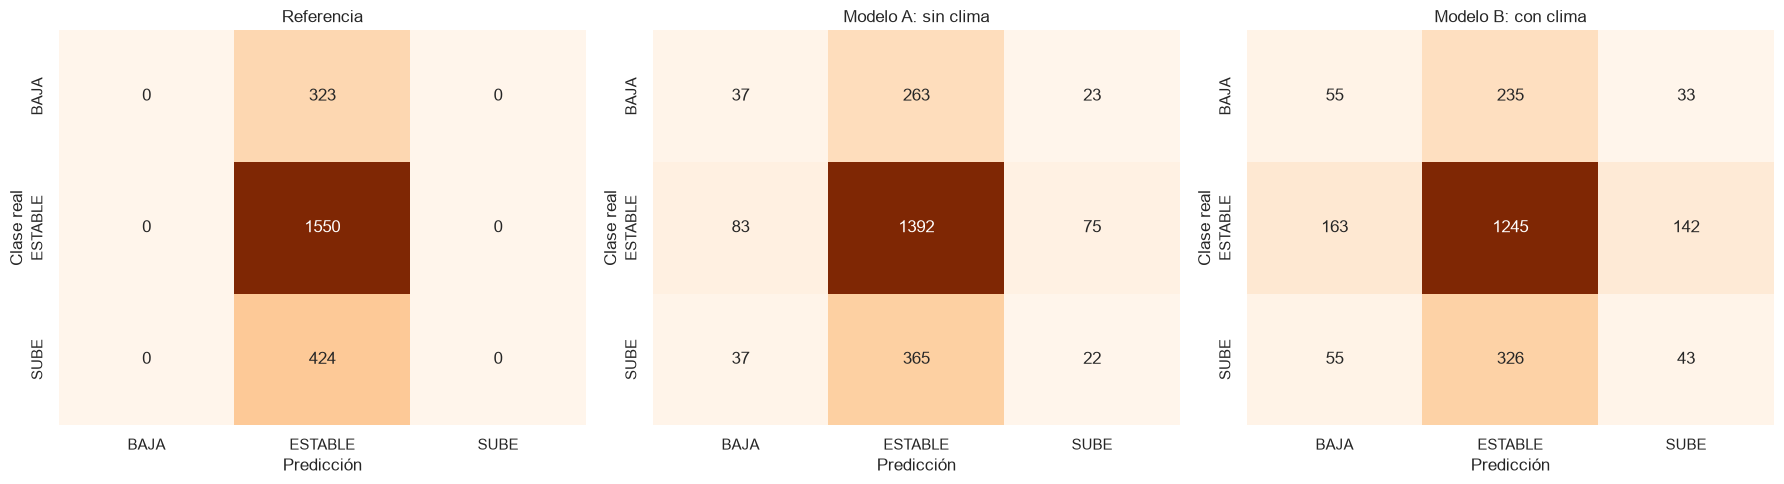

Reporte por clase — Modelo A
              precision    recall  f1-score   support

        BAJA       0.24      0.11      0.15       323
     ESTABLE       0.69      0.90      0.78      1550
        SUBE       0.18      0.05      0.08       424

    accuracy                           0.63      2297
   macro avg       0.37      0.35      0.34      2297
weighted avg       0.53      0.63      0.56      2297

Reporte por clase — Modelo B
              precision    recall  f1-score   support

        BAJA       0.20      0.17      0.18       323
     ESTABLE       0.69      0.80      0.74      1550
        SUBE       0.20      0.10      0.13       424

    accuracy                           0.58      2297
   macro avg       0.36      0.36      0.35      2297
weighted avg       0.53      0.58      0.55      2297



In [19]:
etiquetas = ["BAJA", "ESTABLE", "SUBE"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, pred, titulo in zip(
    axes,
    [pred_base, pred_A, pred_B],
    ["Referencia", "Modelo A: sin clima", "Modelo B: con clima"]
):
    cm = confusion_matrix(y_test, pred, labels=etiquetas)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", cbar=False, ax=ax,
                xticklabels=etiquetas, yticklabels=etiquetas)
    ax.set_title(titulo)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

print("Reporte por clase — Modelo A")
print(classification_report(y_test, pred_A, labels=etiquetas, zero_division=0))
print("Reporte por clase — Modelo B")
print(classification_report(y_test, pred_B, labels=etiquetas, zero_division=0))

**Resultado de la evaluación:** las matrices de confusión y el reporte por clase permiten comprobar que un accuracy alto no necesariamente significa que BAJA y SUBE sean reconocidas correctamente.

## 9. Comparación con y sin variables climáticas

La diferencia se calcula como resultado del Modelo B menos resultado del Modelo A. Una diferencia positiva favorece al modelo con clima y una negativa favorece al modelo sin clima.

In [20]:
comparacion = pd.DataFrame({
    "Modelo A": resultados.loc["Modelo A: sin clima"],
    "Modelo B": resultados.loc["Modelo B: con clima"],
})
comparacion["Diferencia B - A"] = comparacion["Modelo B"] - comparacion["Modelo A"]
display(comparacion.round(3))

delta_bal = comparacion.loc["Balanced accuracy", "Diferencia B - A"]
delta_f1 = comparacion.loc["F1 macro", "Diferencia B - A"]

if delta_bal > 0 and delta_f1 > 0:
    conclusion_clima = (
        "En este bloque de prueba, el Modelo B obtiene una mejora numérica pequeña en balanced accuracy y F1 macro. "
        "Debe confirmarse con validación temporal adicional; no demuestra una mejora robusta ni causalidad."
    )
elif delta_bal < 0 and delta_f1 < 0:
    conclusion_clima = (
        "En este bloque de prueba, añadir clima y Niño 1+2 reduce balanced accuracy y F1 macro. "
        "No hay evidencia de mejora predictiva con estas variables y esta configuración."
    )
else:
    conclusion_clima = (
        "El efecto del clima es mixto: mejora una métrica principal pero empeora la otra. "
        "No puede afirmarse una mejora consistente."
    )

print(conclusion_clima)

,Modelo A,Modelo B,Diferencia B - A
Accuracy,0.632,0.585,-0.047
Balanced accuracy,0.355,0.358,0.003
Precision macro,0.369,0.363,-0.007
Recall macro,0.355,0.358,0.003
F1 macro,0.338,0.353,0.015


En este bloque de prueba, el Modelo B obtiene una mejora numérica pequeña en balanced accuracy y F1 macro. Debe confirmarse con validación temporal adicional; no demuestra una mejora robusta ni causalidad.


**Resultado de la comparación:** la mejora climática debe interpretarse según las métricas reales obtenidas. Una asociación predictiva no demuestra que el clima o El Niño causen la variación del precio.

## 10. Resultados finales

El siguiente bloque imprime automáticamente las métricas reales y la valoración del experimento.

In [21]:
fila_A = resultados.loc["Modelo A: sin clima"]
fila_B = resultados.loc["Modelo B: con clima"]
fila_base = resultados.loc["Referencia: clase mayoritaria"]

print("RESUMEN FINAL")
print("-" * 70)
print(f"Observaciones evaluables comunes: {len(modelo_df):,}")
print(f"Entrenamiento: {len(train_df):,} | Validación: {len(val_df):,} | Prueba: {len(test_df):,}")
print(f"Modelo A: balanced accuracy={fila_A['Balanced accuracy']:.3f}, F1 macro={fila_A['F1 macro']:.3f}")
print(f"Modelo B: balanced accuracy={fila_B['Balanced accuracy']:.3f}, F1 macro={fila_B['F1 macro']:.3f}")
print(f"Referencia: balanced accuracy={fila_base['Balanced accuracy']:.3f}, F1 macro={fila_base['F1 macro']:.3f}")
print(f"Conclusión climática: {conclusion_clima}")

mejor_nombre = "Modelo B" if fila_B["Balanced accuracy"] > fila_A["Balanced accuracy"] else "Modelo A"
mejor_fila = fila_B if mejor_nombre == "Modelo B" else fila_A

if mejor_fila["Balanced accuracy"] <= fila_base["Balanced accuracy"]:
    juicio = (
        "El mejor KNN no supera a la referencia en balanced accuracy. "
        "No se recomienda presentarlo como un predictor útil; el resultado principal es metodológico."
    )
elif mejor_fila["Balanced accuracy"] < 0.55:
    juicio = (
        "El mejor KNN supera la referencia, pero su balanced accuracy sigue siendo modesta. "
        "Debe considerarse un prototipo académico y no una herramienta de decisión comercial."
    )
else:
    juicio = (
        "El mejor KNN supera la referencia en balanced accuracy, aunque aún requiere validación adicional "
        "antes de cualquier uso práctico."
    )
print(f"Valoración: {juicio}")

RESUMEN FINAL
----------------------------------------------------------------------
Observaciones evaluables comunes: 14,605
Entrenamiento: 10,132 | Validación: 2,176 | Prueba: 2,297
Modelo A: balanced accuracy=0.355, F1 macro=0.338
Modelo B: balanced accuracy=0.358, F1 macro=0.353
Referencia: balanced accuracy=0.333, F1 macro=0.269
Conclusión climática: En este bloque de prueba, el Modelo B obtiene una mejora numérica pequeña en balanced accuracy y F1 macro. Debe confirmarse con validación temporal adicional; no demuestra una mejora robusta ni causalidad.
Valoración: El mejor KNN supera la referencia, pero su balanced accuracy sigue siendo modesta. Debe considerarse un prototipo académico y no una herramienta de decisión comercial.


## 11. Conclusiones

- Los tres CSV pueden consolidarse por fecha sin utilizar información futura.
- Los precios mayoristas, minoristas y sus unidades permanecen separados.
- Los Modelos A y B se comparan con las mismas observaciones y periodos.
- Las métricas determinan si el clima aporta una mejora; no se presume causalidad.
- Debido al desbalance de clases, al horizonte irregular y al desempeño modesto, el resultado debe presentarse como prototipo académico.

### Limitaciones principales

- El siguiente registro no corresponde a un horizonte fijo de días.
- El periodo es corto para estudiar completamente fenómenos oceánicos mensuales.
- No se incluyen volumen comercializado, oferta, transporte ni procedencia.
- KNN puede perder efectividad al trabajar con muchas variables categóricas.

### Posibles mejoras

- Incorporar más años y variables comerciales.
- Probar validación temporal con múltiples ventanas.
- Comparar con regresión logística, árboles, Random Forest y boosting.
- Evaluar modelos por categoría o por tipo de precio.